# Model 07 · Will she reply or am I cooked?
Entertainment only. Synthetic data only. No real messages are collected, uploaded or stored.
Two heads: P(reply within 12 h) and the expected wait if she does (log-regression).

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator
Each row is a message with no reply yet. A hidden responsiveness trait shifts both the ghosting odds and the delay.

In [2]:
def generate(n=10000, seed=SEED):
    from scipy.stats import norm
    r = np.random.default_rng(seed)
    d = pd.DataFrame({"minutes_since": np.round(np.exp(r.uniform(0, np.log(1440)))), "avg_reply_min": np.round(np.clip(np.exp(r.normal(3.2, 1.0, n)), 1, 720)),
        "msg_len": np.round(np.clip(np.exp(r.normal(3.8, .9, n)), 1, 400)), "emojis": np.clip(r.poisson(1.4, n), 0, 8),
        "seen": r.choice([0, 1], n, p=[.3, .7]), "hour": np.round(r.uniform(0, 24, n), 1), "day_type": r.choice(["weekday", "weekend"], n, p=[5 / 7, 2 / 7])})
    resp = r.normal(0, 1, n); night = (d.hour < 7).astype(float); wk = (d.day_type == "weekend").astype(float)
    ratio = np.log(d.minutes_since / d.avg_reply_min).clip(-2, 4)
    g = -2.1 + 0.5 * resp + 0.6 * ratio + 0.9 * d.seen + 0.006 * d.msg_len - 0.2 * d.emojis + 0.2 * wk + 0.8 * night
    ghost = r.random(n) < sigmoid(g + r.normal(0, .4, n))
    mu = np.log(d.avg_reply_min) + 0.9 * night + 0.2 * wk + 0.08 * np.log(d.msg_len / 50) - 0.06 * d.emojis + 0.2 * resp + 0.3 - 0.6 * d.seen
    rem = np.clip(np.exp(mu + r.normal(0, .9, n)), 1, 4320)
    d["remaining_min"] = np.round(rem); d["replied_12h"] = ((~ghost) & (rem <= 720)).astype(int)
    d["p_true"] = (1 - sigmoid(g)) * norm.cdf((np.log(720) - mu) / .9); return d

In [3]:
df = generate(10000); df.drop(columns="p_true").to_csv("dataset.csv", index=False)
print(df.shape, "| replied within 12h:", round(df.replied_12h.mean(), 3)); df.drop(columns="p_true").head()

(10000, 10) | replied within 12h: 0.417


,minutes_since,avg_reply_min,msg_len,emojis,seen,hour,day_type,remaining_min,replied_12h
0,278.0,9.0,100.0,1,0,22.4,weekday,6.0,1
1,278.0,52.0,12.0,3,1,14.4,weekday,43.0,1
2,278.0,63.0,35.0,2,1,2.7,weekend,73.0,0
3,278.0,3.0,94.0,0,0,20.6,weekday,4.0,0
4,278.0,7.0,47.0,3,0,7.4,weekday,2.0,1


## 2 · Cleaning + EDA

nulls: 0 | duplicates: 0


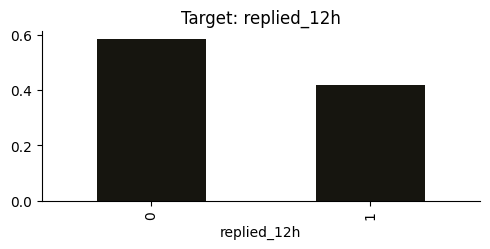

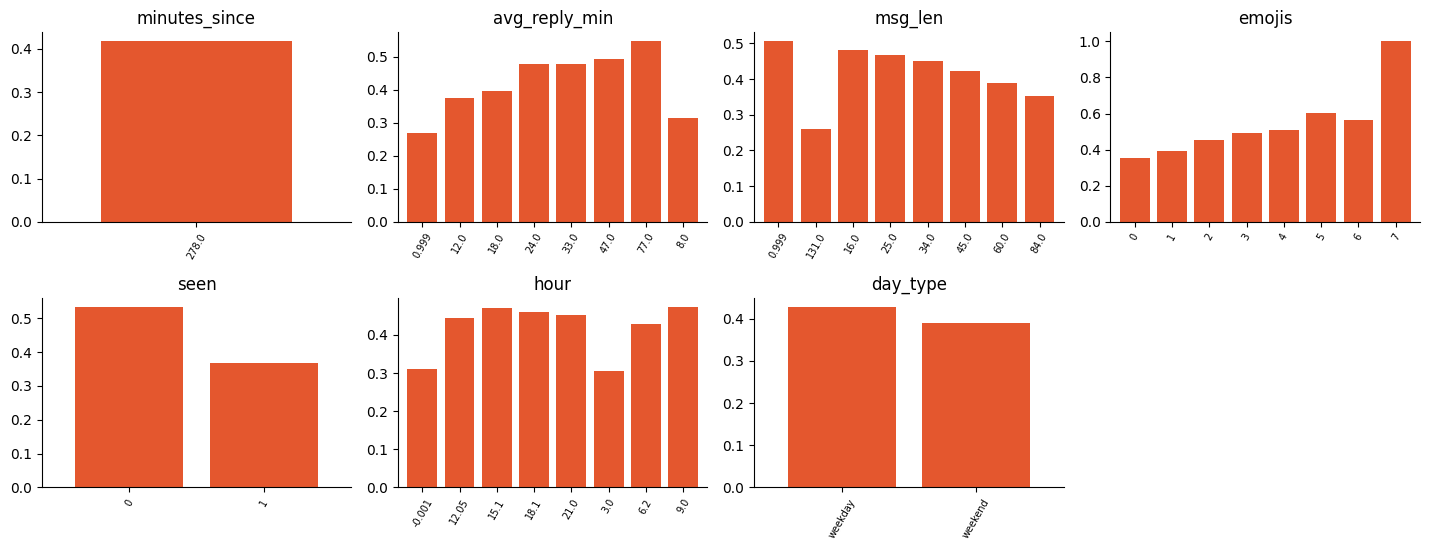

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("minutes_since", 0, 1440, "log1p"), Num("avg_reply_min", 0, 720, "log1p"), Num("msg_len", 0, 400, "log1p"), Num("emojis", 0, 8),
          Num("seen", 0, 1), Num("hour", 0, 24, "cyc"), Cat("day_type", ["weekday", "weekend"])]
RAW = [s["name"] for s in INPUTS]; eda(df, "replied_12h", RAW)

## 3 · Features, split, train both heads
The delay head trains only on rows where a reply happened (otherwise the wait is undefined).

In [5]:
fz = Featurizer(INPUTS); tr, va, te = split3(df, "replied_12h")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
rep, rep_name, table = train_classifier(Xtr, tr.replied_12h, Xva, va.replied_12h, depth=8, leaf=25)
a, b, c = tr.replied_12h == 1, va.replied_12h == 1, te.replied_12h == 1
eta, eta_val = train_regressor(Xtr[a], tr.remaining_min[a].to_numpy(), Xva[b], va.remaining_min[b].to_numpy(), log_target=True, depth=8, leaf=20)
print("reply head:", rep_name, "| eta val MAE (min):", round(eta_val["val_mae"], 1)); table.round(4)

reply head: Logistic Regression | eta val MAE (min): 43.9


,model,val_log_loss,val_accuracy
0,Logistic Regression,0.6150,0.6647
1,Random Forest (isotonic-calibrated),0.6417,0.6540


## 4 · Test evaluation

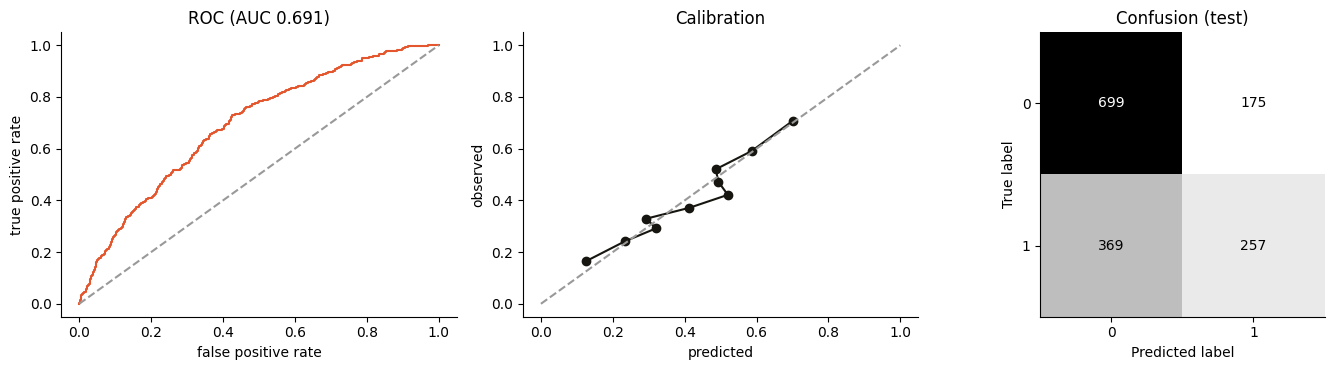

{'accuracy': 0.6373,
 'roc_auc': 0.6912,
 'log_loss': 0.6229,
 'brier': 0.2173,
 'oracle_auc': 0.7392}

In [6]:
m_rep = report_binary(rep, Xte, te.replied_12h); m_rep["oracle_auc"] = round(float(roc_auc_score(te.replied_12h, te.p_true)), 4); m_rep

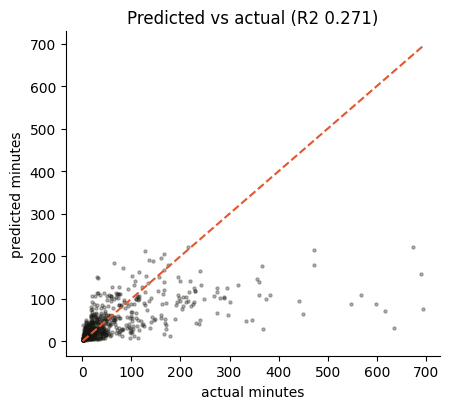

{'mae': 41.4755, 'r2': 0.2707}

In [7]:
m_eta = report_regression(eta, Xte[c], te.remaining_min[c].to_numpy(), "minutes"); m_eta

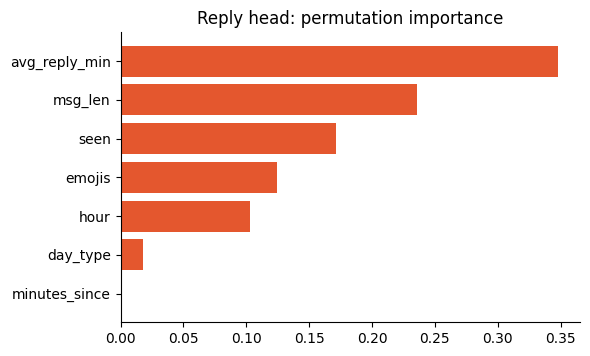

{'avg_reply_min': 0.348,
 'msg_len': 0.2355,
 'seen': 0.171,
 'emojis': 0.1246,
 'hour': 0.1033,
 'day_type': 0.0177,
 'minutes_since': 0.0}

In [8]:
imp = group_importance(lambda X: rep.predict_proba(X)[:, 1], Xte, te.replied_12h.to_numpy(), fz.groups, lambda y, p: log_loss(y, p))
plot_importance(imp, "Reply head: permutation importance"); imp

## 5 · Export + verify

In [9]:
heads = {"reply": export_head(rep, labels=["no", "yes"]), "eta": export_head(eta, task="regression")}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"reply": {"algorithm": rep_name, "task": "binary", "metrics": m_rep, "candidates": table.round(4).to_dict("records")},
     "eta": {"algorithm": "Random Forest Regressor (log target)", "task": "regression", "metrics": m_eta}}, imp,
    ["Entertainment only. Human behavior is unpredictable, especially after 'seen'.", "Trained on synthetic data. No real messages, no relationship data, nothing uploaded."], "generate() in this notebook")
write_artifacts("model", "reply", "Will she reply or am I cooked?", fz, tr, heads, {"reply": rep, "eta": eta}, meta, te[RAW])

wrote model (134 KB total) | export error vs sklearn: {'reply': 5.463316465892376e-10, 'eta': 1.1088774376727314e-06}


{'reply': 5.463316465892376e-10, 'eta': 1.1088774376727314e-06}